<a href="https://colab.research.google.com/github/bhorg15/DSC-212_Assignment/blob/main/dsc212_assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Modularity on the Karate Club Graph**
---
> Recursive Spectral Partitioning of the Karate Club Graph into Communities based on Modularity


##    **Python libraries used:**


> NumPy, MatPlotLib and NetworkX are the libraries used for this assignment. I have also initialised the dictionaries that will store the metrics to be plotted, with each iteration. I also check how many nodes and edges the graph contains, and visualise it once.

**AI usage:**


> Since I am unfamiliar with the NetworkX and MatPlotLib libraries, I needed help from Gemini to find the syntax for some of the built-in functions in order to implement my algorithm involving these libraries.



Number of node: 34
Number of edges: 78


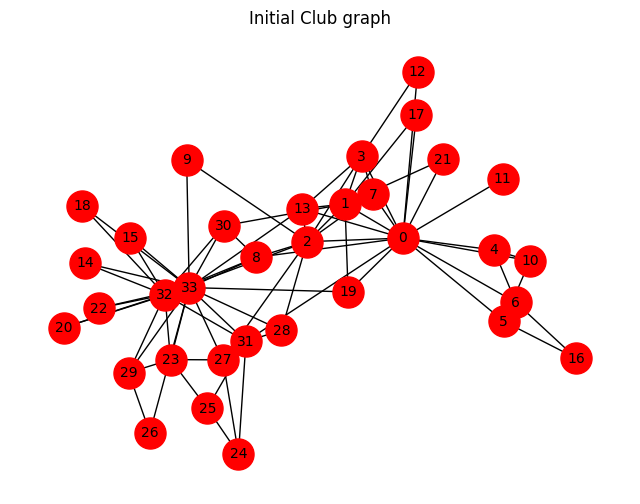

In [22]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt

G=nx.karate_club_graph()
deg={}
bet={}
clo={}
clu={}
iter=0

print("Number of node:",G.number_of_nodes())
print("Number of edges:",G.number_of_edges())

pos=nx.spring_layout(G, seed=32)

plt.figure(figsize=(8,6))
nx.draw_networkx(
    G,
    pos=pos,
    with_labels=True,
    node_color='red',
    edge_color='black',
    node_size=500,
    font_size=10
)

plt.title("Initial Club graph")
plt.axis('off')
plt.show()


# **The Adjacency Matrix, Degree Vector, Transpose of the Degree Vector and the Modularity Matrix**
---
> Since the assignment asks for an unweighted adjacency matrix, I first create a 34x34 matrix with every element 0. Then, I iterate over every element of the matrix and add 1 to Aᵢⱼ if there exists and edge between nodes i and j. At the same time, I utilise this loop to find the degree of node i and find the degree vector as well. I transpose it and find the transpose of the degree vector too. Finally, I use these values to calculate the modularity matrix as well.


In [23]:

a=np.zeros((34,34))
k=np.zeros((34,1))
for i in range(34):
    for j in range(34):
        if G.has_edge(i,j):
            a[i,j] += 1
            k[i,0] += 1

print("The Adjacency Matrix:\n",a)
print("Degree Vector:\n",k)
kt=np.transpose(k)
print("Transpose of the degree vector:\n",kt)

b=a-((np.dot(k,kt))/156)
print("The Modularity Matrix:\n",b)



The Adjacency Matrix:
 [[0. 1. 1. ... 1. 0. 0.]
 [1. 0. 1. ... 0. 0. 0.]
 [1. 1. 0. ... 0. 1. 0.]
 ...
 [1. 0. 0. ... 0. 1. 1.]
 [0. 0. 1. ... 1. 0. 1.]
 [0. 0. 0. ... 1. 1. 0.]]
Degree Vector:
 [[16.]
 [ 9.]
 [10.]
 [ 6.]
 [ 3.]
 [ 4.]
 [ 4.]
 [ 4.]
 [ 5.]
 [ 2.]
 [ 3.]
 [ 1.]
 [ 2.]
 [ 5.]
 [ 2.]
 [ 2.]
 [ 2.]
 [ 2.]
 [ 2.]
 [ 3.]
 [ 2.]
 [ 2.]
 [ 2.]
 [ 5.]
 [ 3.]
 [ 3.]
 [ 2.]
 [ 4.]
 [ 3.]
 [ 4.]
 [ 4.]
 [ 6.]
 [12.]
 [17.]]
Transpose of the degree vector:
 [[16.  9. 10.  6.  3.  4.  4.  4.  5.  2.  3.  1.  2.  5.  2.  2.  2.  2.
   2.  3.  2.  2.  2.  5.  3.  3.  2.  4.  3.  4.  4.  6. 12. 17.]]
The Modularity Matrix:
 [[-1.64102564  0.07692308 -0.02564103 ...  0.38461538 -1.23076923
  -1.74358974]
 [ 0.07692308 -0.51923077  0.42307692 ... -0.34615385 -0.69230769
  -0.98076923]
 [-0.02564103  0.42307692 -0.64102564 ... -0.38461538  0.23076923
  -1.08974359]
 ...
 [ 0.38461538 -0.34615385 -0.38461538 ... -0.23076923  0.53846154
   0.34615385]
 [-1.23076923 -0.69230769  0.23076923 

# **Leading Eigenpair of the Modularity Matrix**


---


> Next, I find the leading eigen pair for the Modularity Matrix. I also initialise a dictionary which stores the sᵢ value (used to assign the nodes a community based on their corresponding value in the leading eigenvector) given in the assignment.




In [24]:
l,u=np.linalg.eigh(b)

l_eva=l[-1]
print("Leading Eigenvalue:",l_eva)
l_eve=u[:,-1]
print("Leading Eigenvector:\n",l_eve)

s_map={}
for node in G.nodes():
  s_map[node]=0


Leading Eigenvalue: 4.977080225729887
Leading Eigenvector:
 [ 0.38754293  0.26955742  0.13189899  0.25345236  0.13400323  0.14573804
  0.14573804  0.20935954 -0.05447571 -0.04785238  0.13400323  0.07784279
  0.12874396  0.13502861 -0.13943288 -0.13943288  0.05851821  0.13197981
 -0.13943288  0.05764888 -0.13943288  0.13197981 -0.13943288 -0.21674712
 -0.0563305  -0.07540039 -0.11580257 -0.10276487 -0.06834027 -0.20629456
 -0.09626391 -0.10185678 -0.32390453 -0.36983786]


# **The Metrics Recording function**
---
> I call this function wherever the metrics are updated and are needed to be stored. This is necessary if we want to plot the evolution of the metrics with each partition.

In [25]:
def rcrd():
  global iter
  print("Iteration:",iter)
  global s_map
  deg[iter]={}
  bet[iter]={}
  clo[iter]={}
  clu[iter]={}

  c_lbls=set(s_map.values())
  for lbl in c_lbls:
    c_nodes=[node for node in s_map.keys() if s_map[node]==lbl]
    subG=G.subgraph(c_nodes)

    if len(c_nodes)>1:
      d=nx.degree_centrality(subG)
      b=nx.betweenness_centrality(subG)
      c=nx.closeness_centrality(subG)
      cl=nx.clustering(subG)

    else:
      d={c_nodes[0]:0.0}
      b={c_nodes[0]:0.0}
      c={c_nodes[0]:0.0}
      cl={c_nodes[0]:0.0}

    deg[iter].update(d)
    bet[iter].update(b)
    clo[iter].update(c)
    clu[iter].update(cl)

  iter+=1
  print("Degree centrality:",deg)
  print("Betweenness centralitiy:",bet)
  print("Closeness centrality:",clo)
  print("Clustering coefficient:",clu)

rcrd()



Iteration: 0
Degree centrality: {0: {0: 0.48484848484848486, 1: 0.2727272727272727, 2: 0.30303030303030304, 3: 0.18181818181818182, 4: 0.09090909090909091, 5: 0.12121212121212122, 6: 0.12121212121212122, 7: 0.12121212121212122, 8: 0.15151515151515152, 9: 0.06060606060606061, 10: 0.09090909090909091, 11: 0.030303030303030304, 12: 0.06060606060606061, 13: 0.15151515151515152, 14: 0.06060606060606061, 15: 0.06060606060606061, 16: 0.06060606060606061, 17: 0.06060606060606061, 18: 0.06060606060606061, 19: 0.09090909090909091, 20: 0.06060606060606061, 21: 0.06060606060606061, 22: 0.06060606060606061, 23: 0.15151515151515152, 24: 0.09090909090909091, 25: 0.09090909090909091, 26: 0.06060606060606061, 27: 0.12121212121212122, 28: 0.09090909090909091, 29: 0.12121212121212122, 30: 0.12121212121212122, 31: 0.18181818181818182, 32: 0.36363636363636365, 33: 0.5151515151515151}}
Betweenness centralitiy: {0: {0: 0.43763528138528146, 1: 0.053936688311688304, 2: 0.14365680615680618, 3: 0.011909271284271

# **The First Split**


---


> First, I iterate over all the nodes using a for loop and assign them a community based on their corresponding value in the leading eigenvector. Next I make a list of colors, basically a color palette to choose from in order to differentiate communities. Next, the graph is visualised after the first split. Finally, the we segregate the nodes into different lists based on the community they belong to. The rcrd function is called here as well, since this is the first iteration.




Segregation: {0: 1, 1: 1, 2: 1, 3: 1, 4: 1, 5: 1, 6: 1, 7: 1, 8: -1, 9: -1, 10: 1, 11: 1, 12: 1, 13: 1, 14: -1, 15: -1, 16: 1, 17: 1, 18: -1, 19: 1, 20: -1, 21: 1, 22: -1, 23: -1, 24: -1, 25: -1, 26: -1, 27: -1, 28: -1, 29: -1, 30: -1, 31: -1, 32: -1, 33: -1}


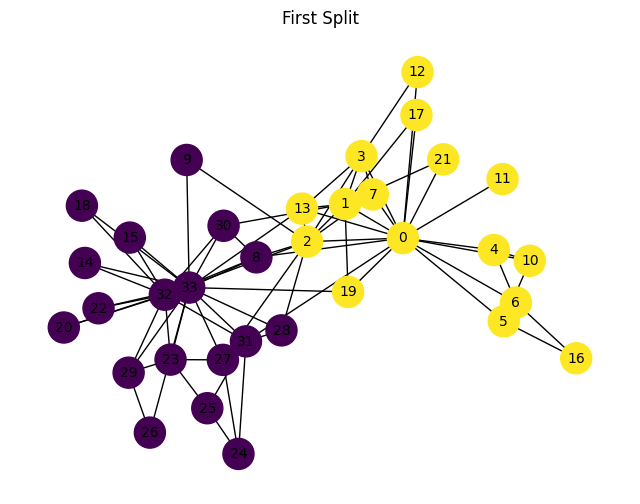

Iteration: 1
Degree centrality: {0: {0: 0.48484848484848486, 1: 0.2727272727272727, 2: 0.30303030303030304, 3: 0.18181818181818182, 4: 0.09090909090909091, 5: 0.12121212121212122, 6: 0.12121212121212122, 7: 0.12121212121212122, 8: 0.15151515151515152, 9: 0.06060606060606061, 10: 0.09090909090909091, 11: 0.030303030303030304, 12: 0.06060606060606061, 13: 0.15151515151515152, 14: 0.06060606060606061, 15: 0.06060606060606061, 16: 0.06060606060606061, 17: 0.06060606060606061, 18: 0.06060606060606061, 19: 0.09090909090909091, 20: 0.06060606060606061, 21: 0.06060606060606061, 22: 0.06060606060606061, 23: 0.15151515151515152, 24: 0.09090909090909091, 25: 0.09090909090909091, 26: 0.06060606060606061, 27: 0.12121212121212122, 28: 0.09090909090909091, 29: 0.12121212121212122, 30: 0.12121212121212122, 31: 0.18181818181818182, 32: 0.36363636363636365, 33: 0.5151515151515151}, 1: {0: 0.9333333333333333, 1: 0.5333333333333333, 2: 0.3333333333333333, 3: 0.4, 4: 0.2, 5: 0.26666666666666666, 6: 0.26666

In [26]:
for id,node in enumerate(G.nodes()):
  if l_eve[id]>0:
    s_map[node]= 1
  else:
    s_map[node]=-1

color_list=[s_map[node] for node in G.nodes()]
print("Segregation:",s_map)
plt.figure(figsize=(8,6))
nx.draw_networkx(
    G,
    pos=pos,
    with_labels=True,
    node_color=color_list,
    edge_color='black',
    node_size=500,
    font_size=10
)

plt.title("First Split")
plt.axis('off')
plt.show()


rcrd()


ls_pls=[]
ls_mns=[]
for i in s_map.keys():
  if s_map[i]>0:
    ls_pls.append(i)
  else:
    ls_mns.append(i)

print("Community (+1):",ls_pls)
print("Community (-1):",ls_mns)
split_s=2



# **The Recursive Spectral Partitioning Function**
---
> We pass the lists of the communities created to this function, and implement the same logic used above with a few changes:
*   Bᶜ: As the assignment states, we consider a block of the original Modularity Matrix corresponding to the nodes in the list passed as an argument.

**Base Cases:**
1.   If the community contains only one node, the recursion is terminated.
2.   If the leading eigenvalue of the modularity matrix is 0, the recursion is terminated.
3.   If after the partition, we get only one community, the recursion is terminated.

Modularity Matrix for the community:
 [[-1.64102564  0.07692308 -0.02564103  0.38461538  0.69230769  0.58974359
   0.58974359  0.58974359  0.69230769  0.8974359   0.79487179  0.48717949
  -0.20512821  0.79487179  0.69230769  0.79487179]
 [ 0.07692308 -0.51923077  0.42307692  0.65384615 -0.17307692 -0.23076923
  -0.23076923  0.76923077 -0.17307692 -0.05769231 -0.11538462  0.71153846
  -0.11538462  0.88461538  0.82692308  0.88461538]
 [-0.02564103  0.42307692 -0.64102564  0.61538462 -0.19230769 -0.25641026
  -0.25641026  0.74358974 -0.19230769 -0.06410256 -0.12820513  0.67948718
  -0.12820513 -0.12820513 -0.19230769 -0.12820513]
 [ 0.38461538  0.65384615  0.61538462 -0.23076923 -0.11538462 -0.15384615
  -0.15384615  0.84615385 -0.11538462 -0.03846154  0.92307692  0.80769231
  -0.07692308 -0.07692308 -0.11538462 -0.07692308]
 [ 0.69230769 -0.17307692 -0.19230769 -0.11538462 -0.05769231 -0.07692308
   0.92307692 -0.07692308  0.94230769 -0.01923077 -0.03846154 -0.09615385
  -0.03846154 -0.0

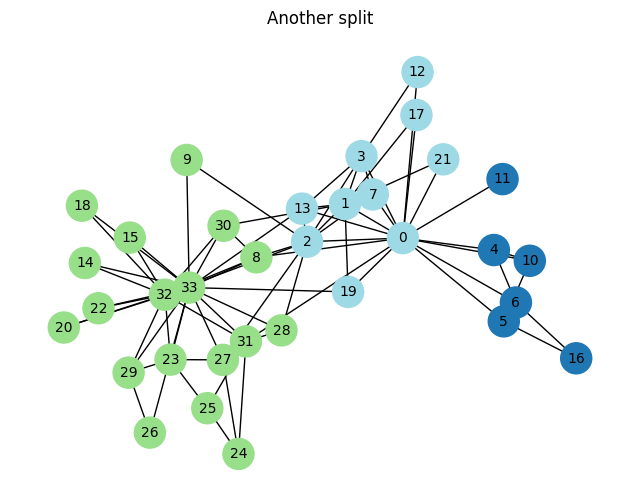

Iteration: 2
Degree centrality: {0: {0: 0.48484848484848486, 1: 0.2727272727272727, 2: 0.30303030303030304, 3: 0.18181818181818182, 4: 0.09090909090909091, 5: 0.12121212121212122, 6: 0.12121212121212122, 7: 0.12121212121212122, 8: 0.15151515151515152, 9: 0.06060606060606061, 10: 0.09090909090909091, 11: 0.030303030303030304, 12: 0.06060606060606061, 13: 0.15151515151515152, 14: 0.06060606060606061, 15: 0.06060606060606061, 16: 0.06060606060606061, 17: 0.06060606060606061, 18: 0.06060606060606061, 19: 0.09090909090909091, 20: 0.06060606060606061, 21: 0.06060606060606061, 22: 0.06060606060606061, 23: 0.15151515151515152, 24: 0.09090909090909091, 25: 0.09090909090909091, 26: 0.06060606060606061, 27: 0.12121212121212122, 28: 0.09090909090909091, 29: 0.12121212121212122, 30: 0.12121212121212122, 31: 0.18181818181818182, 32: 0.36363636363636365, 33: 0.5151515151515151}, 1: {0: 0.9333333333333333, 1: 0.5333333333333333, 2: 0.3333333333333333, 3: 0.4, 4: 0.2, 5: 0.26666666666666666, 6: 0.26666

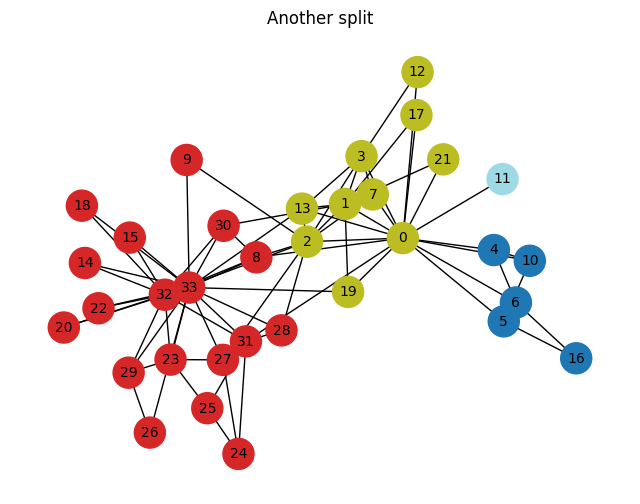

Iteration: 3
Degree centrality: {0: {0: 0.48484848484848486, 1: 0.2727272727272727, 2: 0.30303030303030304, 3: 0.18181818181818182, 4: 0.09090909090909091, 5: 0.12121212121212122, 6: 0.12121212121212122, 7: 0.12121212121212122, 8: 0.15151515151515152, 9: 0.06060606060606061, 10: 0.09090909090909091, 11: 0.030303030303030304, 12: 0.06060606060606061, 13: 0.15151515151515152, 14: 0.06060606060606061, 15: 0.06060606060606061, 16: 0.06060606060606061, 17: 0.06060606060606061, 18: 0.06060606060606061, 19: 0.09090909090909091, 20: 0.06060606060606061, 21: 0.06060606060606061, 22: 0.06060606060606061, 23: 0.15151515151515152, 24: 0.09090909090909091, 25: 0.09090909090909091, 26: 0.06060606060606061, 27: 0.12121212121212122, 28: 0.09090909090909091, 29: 0.12121212121212122, 30: 0.12121212121212122, 31: 0.18181818181818182, 32: 0.36363636363636365, 33: 0.5151515151515151}, 1: {0: 0.9333333333333333, 1: 0.5333333333333333, 2: 0.3333333333333333, 3: 0.4, 4: 0.2, 5: 0.26666666666666666, 6: 0.26666

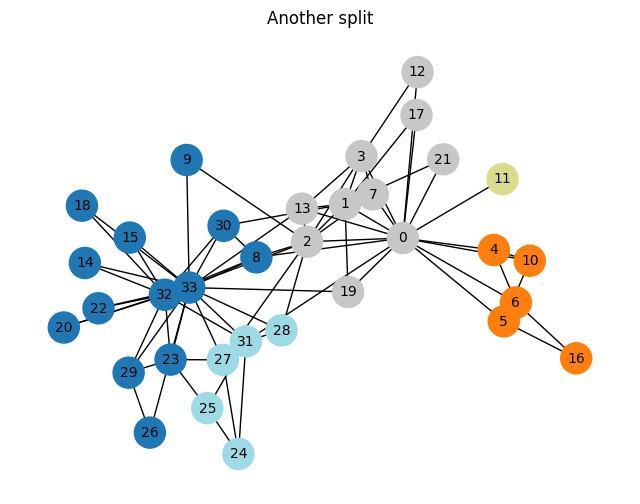

Iteration: 4
Degree centrality: {0: {0: 0.48484848484848486, 1: 0.2727272727272727, 2: 0.30303030303030304, 3: 0.18181818181818182, 4: 0.09090909090909091, 5: 0.12121212121212122, 6: 0.12121212121212122, 7: 0.12121212121212122, 8: 0.15151515151515152, 9: 0.06060606060606061, 10: 0.09090909090909091, 11: 0.030303030303030304, 12: 0.06060606060606061, 13: 0.15151515151515152, 14: 0.06060606060606061, 15: 0.06060606060606061, 16: 0.06060606060606061, 17: 0.06060606060606061, 18: 0.06060606060606061, 19: 0.09090909090909091, 20: 0.06060606060606061, 21: 0.06060606060606061, 22: 0.06060606060606061, 23: 0.15151515151515152, 24: 0.09090909090909091, 25: 0.09090909090909091, 26: 0.06060606060606061, 27: 0.12121212121212122, 28: 0.09090909090909091, 29: 0.12121212121212122, 30: 0.12121212121212122, 31: 0.18181818181818182, 32: 0.36363636363636365, 33: 0.5151515151515151}, 1: {0: 0.9333333333333333, 1: 0.5333333333333333, 2: 0.3333333333333333, 3: 0.4, 4: 0.2, 5: 0.26666666666666666, 6: 0.26666

In [27]:
def rcur_splt(lst):
  if len(lst)<=1:
    return
  global split_s
  b_c=np.zeros((len(lst),len(lst)))
  for i in range(len(lst)):
    for j in range(len((lst))):
      b_c[i][j]=b[lst[i]][lst[j]]
  print("Modularity Matrix for the community:\n",b_c)
  l_c,u_c=np.linalg.eigh(b_c)
  l_l_c=l_c[-1]
  print("Leading Eigenvalue:\n",l_l_c)
  l_u_c=u_c[:,-1]
  print("Leading Eigenvector:\n",l_u_c)

  if l_l_c<=0:
    print("No more splitting will improve modularity")
    return
  else:
    sub_pls=[]
    sub_mns=[]
    for id in range(len(lst)):
      node=lst[id]
      if l_u_c[id]>0:
        sub_pls.append(node)
      else:
        sub_mns.append(node)
    print("Segregation:",s_map)
  if len(sub_pls)==0 or len(sub_mns)==0:
    print("No more splitting will improve modularity")
    return

  for node in sub_pls:
    s_map[node]=+split_s
  for node in sub_mns:
    s_map[node]=-split_s
  split_s+=1
  color_list=[s_map[node] for node in G.nodes()]
  plt.figure(figsize=(8,6))
  nx.draw_networkx(
        G,
        pos=pos,
        with_labels=True,
        node_color=color_list,
        cmap=plt.cm.tab20,
        edge_color='black',
        node_size=500,
        font_size=10
    )

  plt.title("Another split")
  plt.axis('off')
  plt.show()

  rcrd()

  rcur_splt(sub_pls)
  rcur_splt(sub_mns)



rcur_splt(ls_pls)
rcur_splt(ls_mns)



# **Evolution of the Metrics with each Iteration**

---


>This part was majorly done by AI, since I do not have enough experience with MatPlotLib. However, this helped me learn a lot about plotting values from dictionaries.

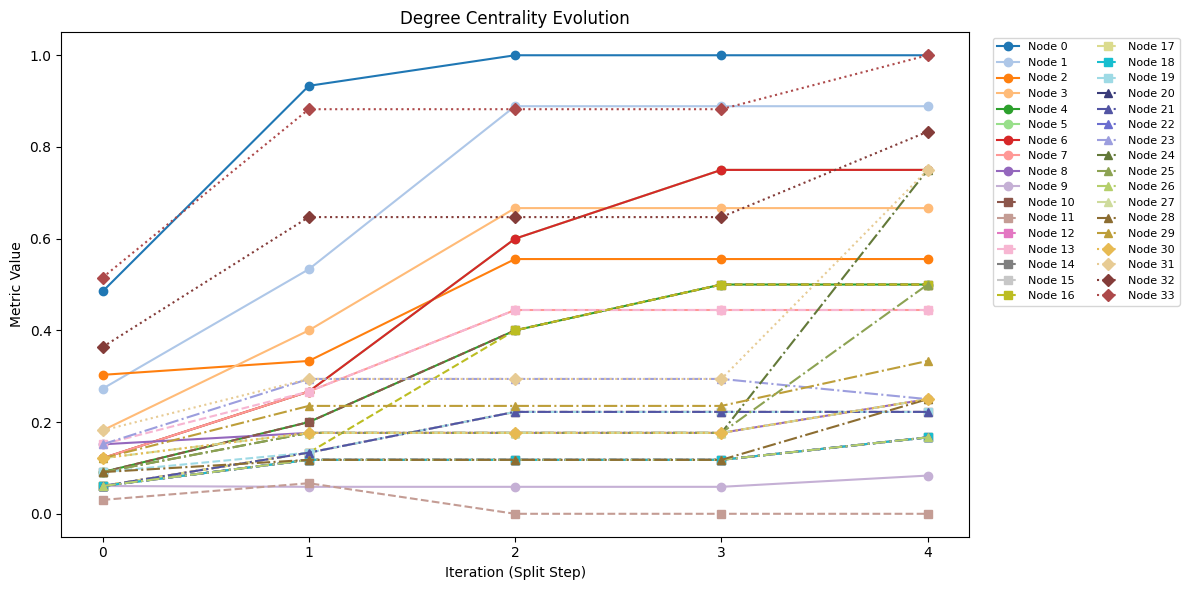

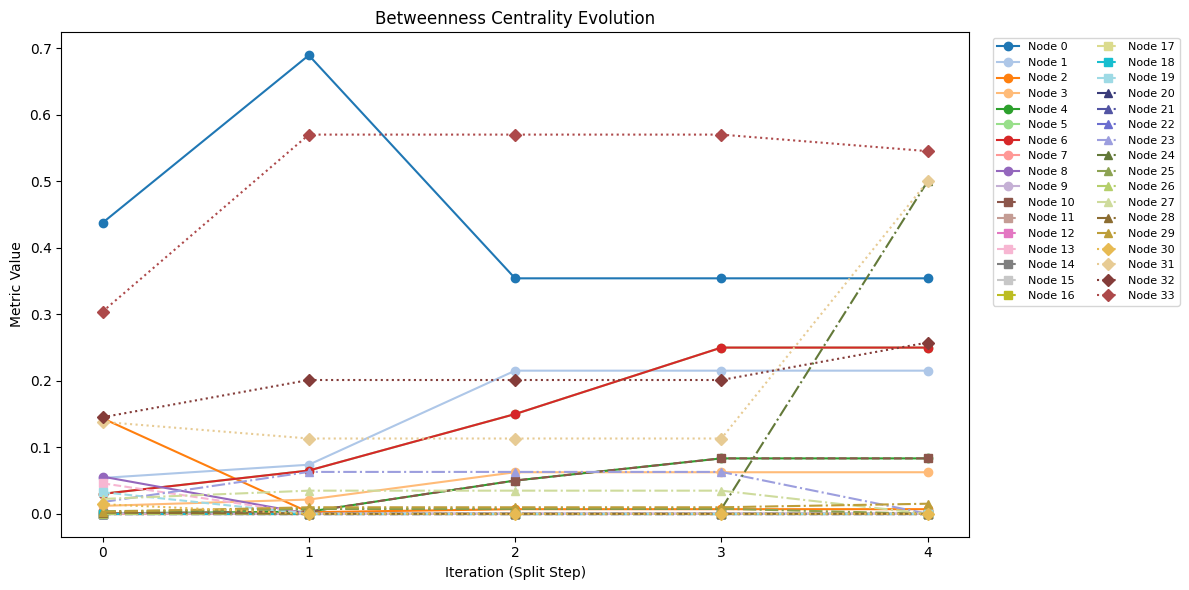

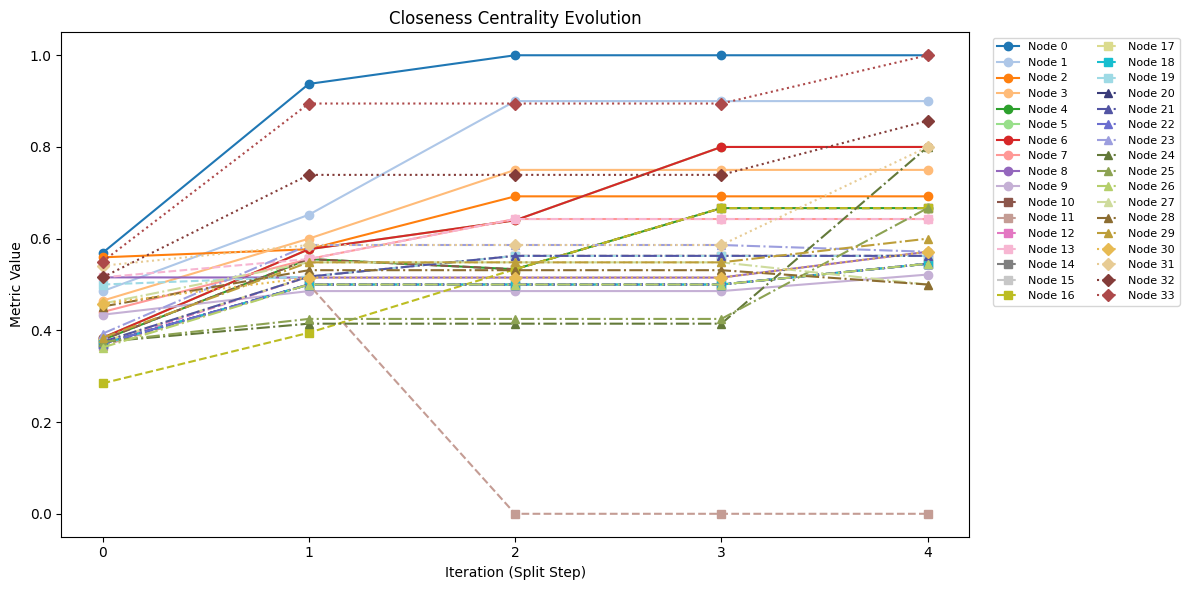

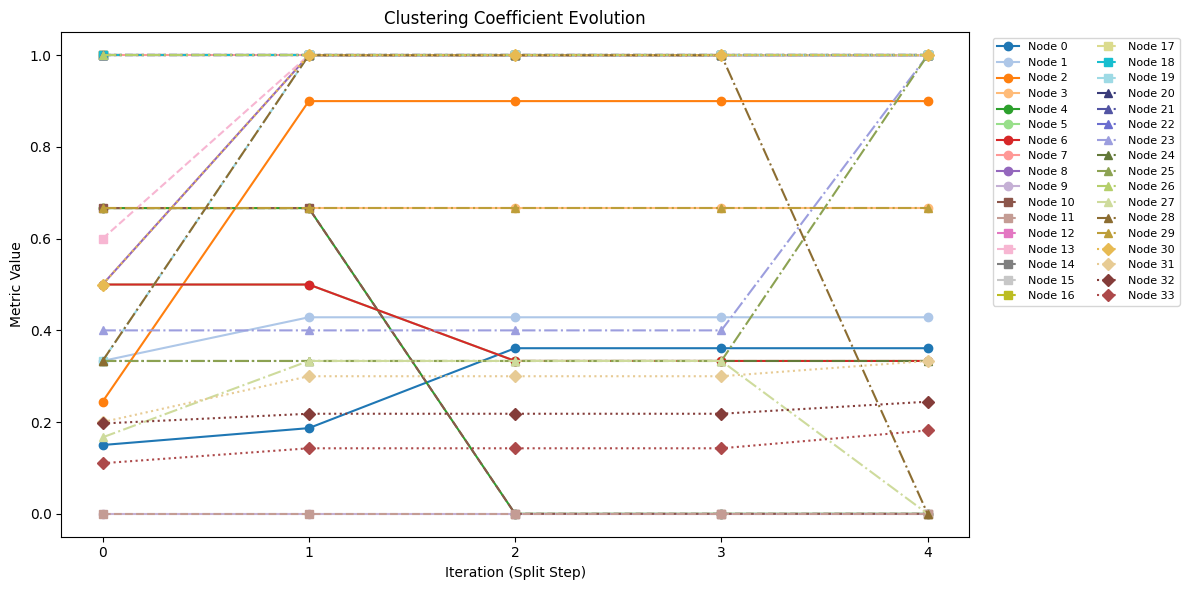

In [30]:
metrics_to_plot = [
    (deg, "Degree Centrality Evolution"),
    (bet, "Betweenness Centrality Evolution"),
    (clo, "Closeness Centrality Evolution"),
    (clu, "Clustering Coefficient Evolution")
]

# 4 distinct line styles and 4 marker shapes so every 10-node cycle looks completely different
line_styles = ['-', '--', '-.', ':']
markers = ['o', 's', '^', 'D']

# Build a 40-color palette by combining tab20 and tab20b so all 34 nodes get unique colors
colors_34 = list(plt.cm.tab20.colors) + list(plt.cm.tab20b.colors)

for hist_dict, title_name in metrics_to_plot:
  plt.figure(figsize=(12, 6))

  iters = list(hist_dict.keys())

  for node in G.nodes():
    y_vals = [hist_dict[i][node] for i in iters]

    # Every group of 10 nodes (0-9, 10-19, 20-29, 30-33) gets a different line style & marker
    style_idx = node // 10

    plt.plot(
        iters,
        y_vals,
        color=colors_34[node],
        linestyle=line_styles[style_idx],
        marker=markers[style_idx],
        label=f"Node {node}"
    )

  plt.title(title_name)
  plt.xlabel("Iteration (Split Step)")
  plt.ylabel("Metric Value")
  plt.xticks(iters)

  plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', ncol=2, fontsize=8)
  plt.tight_layout()
  plt.show()

# **Discussion on the Metrics of the Nodes**


---
**Nodes that consistently remain central:**


> In the Degree Centrality and closeness centrality plot, we observe that both nodes, 0 and 33, start at the highest values (implying they were already quite popular in the original network) and by the end of the iterations, reach a value of 1, which indicates that they are connected to pretty much all the members in their respective communities and are the best "spreaders" in their respective networks.



**The Influence of the Community Structure on the Metrics:**


> **Degree and Closeness Centrality:** Since spectral modularity maximization cuts sparse inter-community edges while preserving dense intra-community edges, nodes retain almost all of their neighbors while the denominator shrinks with each split. Hence, the degree and closeness centrality scores for well connected nodes increases with each split in the community.


> **Betweenness Centrality:** Nodes 0 and 33 started off with the highest Betweenness centrality, with nodes 31 and 24 stepping up as well by the final iteration. This is reflected in the plots, since 0 and 33 have always been important brokers between the peripheral communities and the central communities, whereas node 31 ends up connecting the grey and blue communities after the final split, making it an important bridge between the communities.


> **Clustering Coefficient:** Since recursive splitting removes sparse inter-community edges while keeping tightly connected internal neighbors, the clustering coefficients for many core nodes jump to 1.0,(forming complete local cliques within their sub-community), whereas nodes left in tree-like or star-like fragments without triangles (such as in the [24, 25, 27, 28, 31] split at Iteration 4) drop to 0.0



**References:**  Newman (2006), “Modularity and community structure in
networks,” PNAS 103(23):8577–8582.